# Activation Foil Analysis: FLiBe 1L BABY Run #4

This notebook processes the calibration data from NaI detectors to energy calibrate the detectors and determine total detector efficiencies. Then, NaI measurements of activation foils irradiated during the run with a D-T neutron (14.1 MeV) generator are used to determine the average neutron rate during the run. 

## Obtaining the Data
First, the NaI detector measurement data is obtained from Zenodo and extracted

In [1]:
# parameters

## keep this if statement for ci and process workflows
if 'download_from_raw' not in globals() and 'download_from_raw' not in locals():
    download_from_raw = False

In [2]:
import numpy as np
from datetime import datetime
import json
from libra_toolbox.neutron_detection.activation_foils import compass
from matplotlib import pyplot as plt

In [3]:
from process_foil_data import get_data

detector_type = "NaI"
check_source_measurements, background_meas, foil_measurements = get_data(download_from_raw=download_from_raw,
                                                                         h5_filename="activation_data.h5",
                                                                         detector_type=detector_type)

Available detector types:  ['NaI']
Read in properties of Zirconium Packet #10 foil
Read in properties of Zirconium Packet #9 foil
Read in properties of Niobium Packet #11 foil
Read in properties of Niobium Packet #12 foil
Processing Background from h5 file...
Processing Co60 Count 1 from h5 file...
Processing Co60 Count 2 from h5 file...
Processing Cs137 Count 1 from h5 file...
Processing Cs137 Count 2 from h5 file...
Processing Mn54 Count 1 from h5 file...
Processing Mn54 Count 2 from h5 file...
Processing Na22 Count 1 from h5 file...
Processing Na22 Count 2 from h5 file...
Processing Niobium Packet #11 Count 1 from h5 file...
Processing Niobium Packet #11 Count 2 from h5 file...
Processing Niobium Packet #12 Count 1 from h5 file...
Processing Niobium Packet #12 Count 2 from h5 file...
Processing Zirconium Packet #10 Count 1 from h5 file...
Processing Zirconium Packet #10 Count 2 from h5 file...
Processing Zirconium Packet #9 Count 1 from h5 file...
Processing Zirconium Packet #9 Coun

Using custom peak finding parameters from kwargs:  {'start_index': 400, 'prominence': None, 'height': np.float64(414.0), 'width': [10, 150], 'distance': 30}
Using custom peak finding parameters from kwargs:  {'start_index': 400, 'prominence': None, 'height': np.float64(673.8), 'width': [10, 150], 'distance': 30}
Using custom peak finding parameters from kwargs:  {'start_index': 400, 'prominence': None, 'height': np.float64(343.8), 'width': [10, 150], 'distance': 30}
Using custom peak finding parameters from kwargs:  {'start_index': 400, 'prominence': None, 'height': np.float64(550.8), 'width': [10, 150], 'distance': 30}
Using custom peak finding parameters from kwargs:  {'height': np.float64(3575.5)}
Using custom peak finding parameters from kwargs:  {'start_index': 100, 'prominence': np.float64(715.1), 'height': np.float64(3575.5), 'width': [10, 150], 'distance': 30}
Using custom peak finding parameters from kwargs:  {'height': np.float64(6078.5)}
Using custom peak finding parameters 

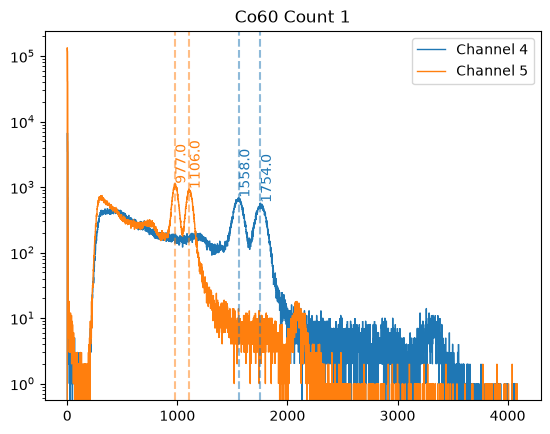

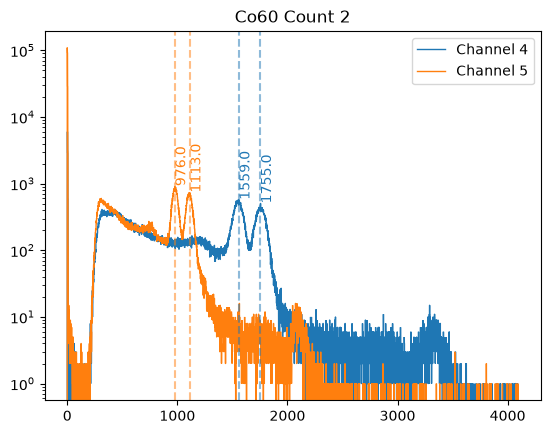

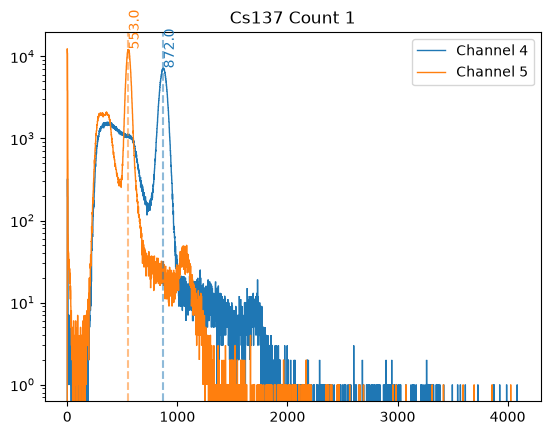

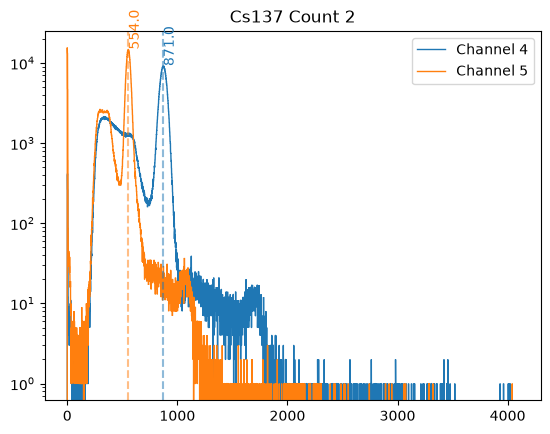

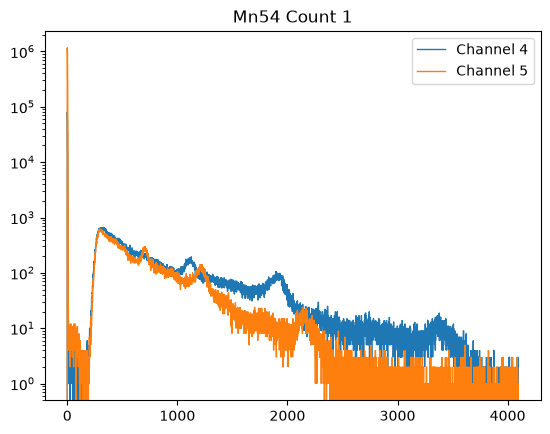

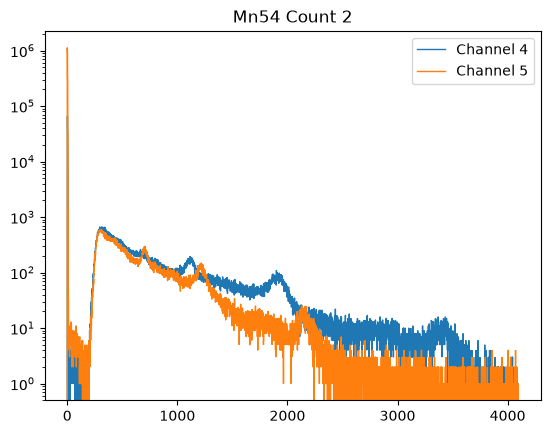

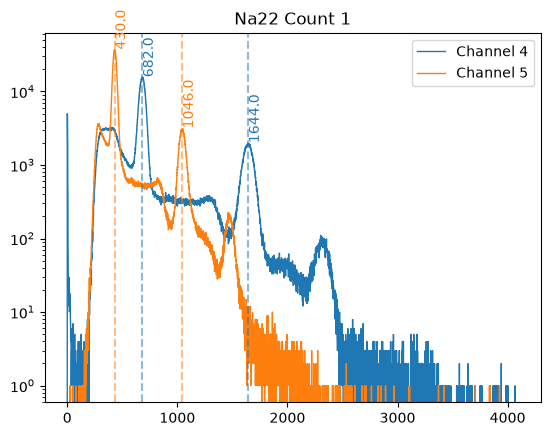

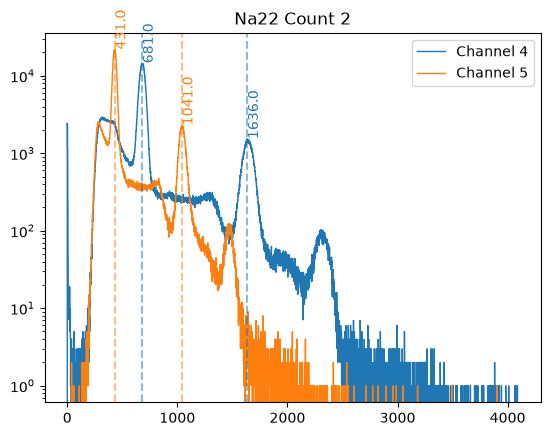

In [4]:
from scipy.signal import find_peaks
channels = [4, 5]
colors = ['tab:blue', 'tab:orange']

for name, measurement in check_source_measurements.items():
    fig, ax = plt.subplots()
    for color, ch in zip(colors, channels):
        det = measurement.get_detector(ch)
        hist, xvals = det.get_energy_hist()
        special_peak_kwargs = {'Na22': {'start_index': 100,
                                        'width': [10, 300],
                                        'distance': 400,
                                        'height': hist[100:].max() * 0.01,
                                        'prominence': hist[100:].max() * 0.01
                                    },
                                    "Cs137": {"height": hist[100:].max() * 0.5}
                    }
        if name.split()[0] not in special_peak_kwargs:
            special_peak_kwargs[name.split()[0]] = {}
        peak_kwargs = measurement.get_peak_fitting_parameters(hist, **special_peak_kwargs[name.split()[0]])
        if name=='Na22 Count 1' and ch==4:
            print(peak_kwargs)
        peaks = measurement.get_peaks(hist, **peak_kwargs)
        ax.stairs(hist, xvals, label=f'Channel {ch}', color=color)
        for peak in peaks:
            ax.axvline(xvals[peak], color=color, linestyle='--', alpha=0.5)
            ax.text(xvals[peak], hist[peak], f'{xvals[peak]:.1f}', rotation=90, verticalalignment='bottom',
                    color=color)
        
    ax.legend()
    ax.set_title(name)
    ax.set_yscale('log')
    

## Energy Calibration

Using gamma check sources like Co-60 and Cs-137, the characteristic photon peaks from these sources are used to convert the digitizer channel bins into energy (keV) bins

Calibrating channel 4...
Using custom peak finding parameters from kwargs:  {'height': np.float64(3575.5)}
Using custom peak finding parameters from kwargs:  {'height': np.float64(3575.5)}
Using custom peak finding parameters from kwargs:  {'start_index': 100, 'width': [10, 200], 'distance': 400, 'prominence': np.float64(145.25), 'height': np.float64(145.25)}
Using custom peak finding parameters from kwargs:  {'start_index': 100, 'width': [10, 200], 'distance': 400, 'prominence': np.float64(145.25), 'height': np.float64(145.25)}
Calibrating channel 5...
Using custom peak finding parameters from kwargs:  {'height': np.float64(6078.5)}
Using custom peak finding parameters from kwargs:  {'height': np.float64(6078.5)}
Using custom peak finding parameters from kwargs:  {'start_index': 100, 'width': [10, 200], 'distance': 400, 'prominence': np.float64(217.99), 'height': np.float64(217.99)}
Using custom peak finding parameters from kwargs:  {'start_index': 100, 'width': [10, 200], 'distance':

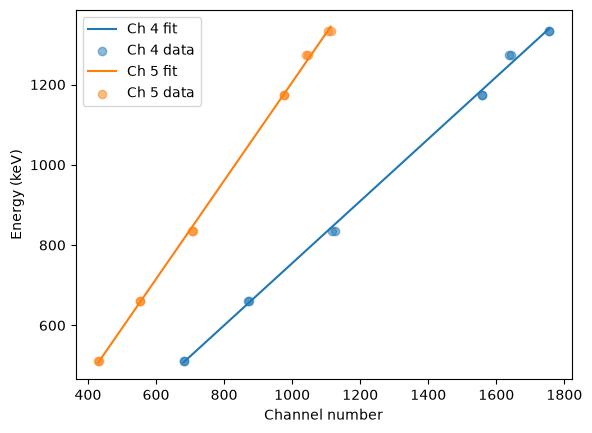

In [5]:
calibration_coeffs = {}


for ch in channels:
    print(f"Calibrating channel {ch}...")
    # mn54_hist = check_source_measurements["Mn54 Count 1"].get_detector(ch).get_energy_hist()[0]
    cs137_hist = check_source_measurements["Cs137 Count 1"].get_detector(ch).get_energy_hist()[0]
    na22_hist_1 = check_source_measurements["Na22 Count 1"].get_detector(ch).get_energy_hist()[0]
    na22_hist_2 = check_source_measurements["Na22 Count 2"].get_detector(ch).get_energy_hist()[0]
    peak_kwargs = {'Na22': {'start_index': 100,
                        # 'prominence': mn54_hist[100:].max() * 0.1,
                        'width': [10, 200],
                        'distance': 400,
                        'prominence': np.min([na22_hist_1[100:].max(), na22_hist_2[100:].max()]) * 0.01,
                        'height': np.min([na22_hist_1[100:].max(), na22_hist_2[100:].max()]) * 0.01
                    },
                    "Cs137": {"height": cs137_hist[100:].max() * 0.5}
    }
    calibration_channels, calibration_energies = compass.get_calibration_data(
        check_source_measurements.values(),
        background_measurement=background_meas,
        channel_nb=ch,
        peak_kwargs=peak_kwargs
    )

    coeff = np.polyfit(calibration_channels, calibration_energies, 1)
    calibration_coeffs[ch] = coeff

    xs = np.linspace(
        calibration_channels[0],
        calibration_channels[-1],
    )
    plt.plot(
        xs,
        np.polyval(coeff, xs),
        label=f"Ch {ch} fit",
    )
    plt.scatter(
        calibration_channels,
        calibration_energies,
        label=f"Ch {ch} data",
        alpha=0.5,
    )
    plt.xlabel("Channel number")
    plt.ylabel("Energy (keV)")
    plt.legend()
plt.show()

## Detector Efficiency

Using these same check-sources, each with a known activity, an efficiency curve for each detector is calculated. 

Two types of efficiency curves are shown: 
1. Exponent of sum of logarithms (used in https://doi.org/10.2172/1524045): $ y = \exp(\sum_{i=0}^n a_n \log(E)^i) $

2. Polynomial fit (3rd order): $ y = \sum_{i=0}^n a_n E^i $

**Only the polynomal fit is currently implemented in libra-toolbox, so that is the curve that will be used to calculate the efficiency of the detectors at measuring the activity of the activation foil peaks.**

In [6]:
for name, measurement in check_source_measurements.items():
    for detector in measurement.detectors:
        dead_time_fraction = 1 - detector.live_count_time / detector.real_count_time
        print(f"{name} Ch {detector.channel_nb} \n\t Live time: {detector.live_count_time} s \n\t Real time: {detector.real_count_time} s")
        print(f"\t Dead time fraction: {dead_time_fraction:.2%}")

Co60 Count 1 Ch 4 
	 Live time: 1310.945 s 
	 Real time: 1311.728 s
	 Dead time fraction: 0.06%
Co60 Count 1 Ch 5 
	 Live time: 1309.765 s 
	 Real time: 1311.727 s
	 Dead time fraction: 0.15%
Co60 Count 2 Ch 4 
	 Live time: 1055.642 s 
	 Real time: 1056.313 s
	 Dead time fraction: 0.06%
Co60 Count 2 Ch 5 
	 Live time: 1054.755 s 
	 Real time: 1056.313 s
	 Dead time fraction: 0.15%
Cs137 Count 1 Ch 4 
	 Live time: 120.747 s 
	 Real time: 122.191 s
	 Dead time fraction: 1.18%
Cs137 Count 1 Ch 5 
	 Live time: 120.755 s 
	 Real time: 122.191 s
	 Dead time fraction: 1.18%
Cs137 Count 2 Ch 4 
	 Live time: 149.658 s 
	 Real time: 151.525 s
	 Dead time fraction: 1.23%
Cs137 Count 2 Ch 5 
	 Live time: 149.808 s 
	 Real time: 151.525 s
	 Dead time fraction: 1.13%
Mn54 Count 1 Ch 4 
	 Live time: 11251.155 s 
	 Real time: 11253.405 s
	 Dead time fraction: 0.02%
Mn54 Count 1 Ch 5 
	 Live time: 11241.128 s 
	 Real time: 11253.404 s
	 Dead time fraction: 0.11%
Mn54 Count 2 Ch 4 
	 Live time: 10934.33

In [7]:
def eff_curve_func(E, *a):
    exponent_term = 0
    for i,a_n in enumerate(a):
        exponent_term += a_n * (np.log(E) ** i)
    return np.exp(exponent_term)

[1186.5932506  1338.26803892]
Fitted parameters: [ 3.72188205e+02 -2.47129560e-01  5.67254449e+02  1.18368538e+03
  3.26617774e+01  4.75437078e+02  1.34183745e+03  3.58995193e+01]

[1187.36710156 1339.04188989]
Fitted parameters: [ 3.03022355e+02 -2.01148847e-01  4.67603892e+02  1.18287073e+03
  3.28277225e+01  3.92990622e+02  1.34123838e+03  3.57019402e+01]



/tmp/ipykernel_19711/3936937588.py:61: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend()


[655.73149147]
Fitted parameters: [ 1.47061447e+03 -1.77360470e+00  6.84778712e+03  6.56133564e+02
 -2.21063903e+01]

[654.9576405]
Fitted parameters: [ 1.76162504e+03 -2.12172277e+00  8.78165173e+03  6.56345630e+02
 -2.21948249e+01]

[852.28963552]
Fitted parameters: [ 1.61362243e+01 -1.38205767e-02  7.83918285e+01  8.42684978e+02
 -2.67383494e+01]

[844.55112591]
Fitted parameters: [ 1.60093220e+01 -1.49665840e-02  8.10889172e+01  8.44003986e+02
  2.70693770e+01]

[ 508.69980891 1253.14443323]
[np.float64(508.69980890644587)]
Fitted parameters: [ 3.85967568e+03 -5.16722714e+00  1.43802723e+04  5.08515754e+02
 -1.86596872e+01]
[np.float64(1253.1444332323288)]
Fitted parameters: [ 6.87145430e+02 -4.45966005e-01  1.78409109e+03  1.25241046e+03
  3.39856170e+01]

[ 507.92595795 1246.95362555]
[np.float64(507.9259579456081)]
Fitted parameters: [ 3.28652299e+03 -4.44937043e+00  1.35083330e+04  5.08513333e+02
 -1.86304108e+01]
[np.float64(1246.953625545627)]
Fitted parameters: [ 5.37885333e

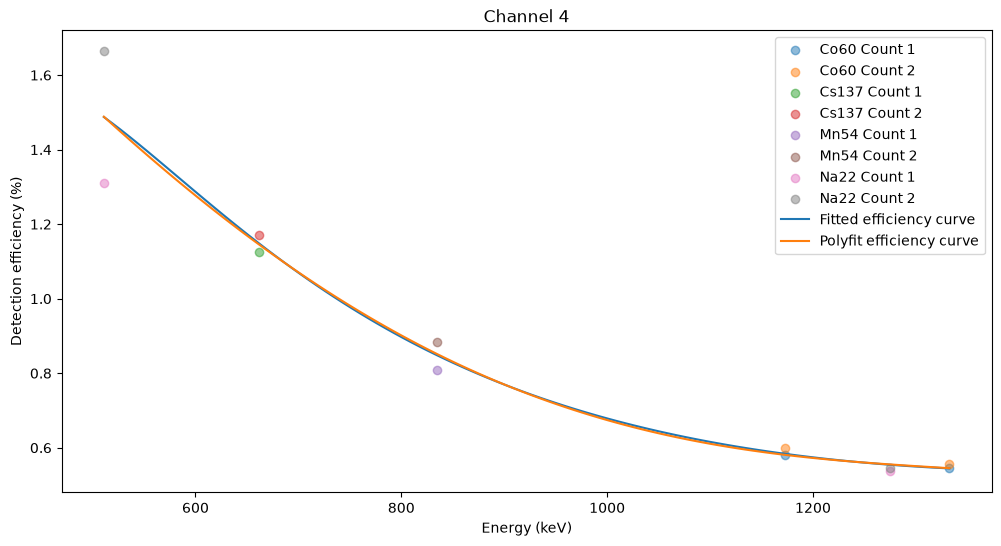

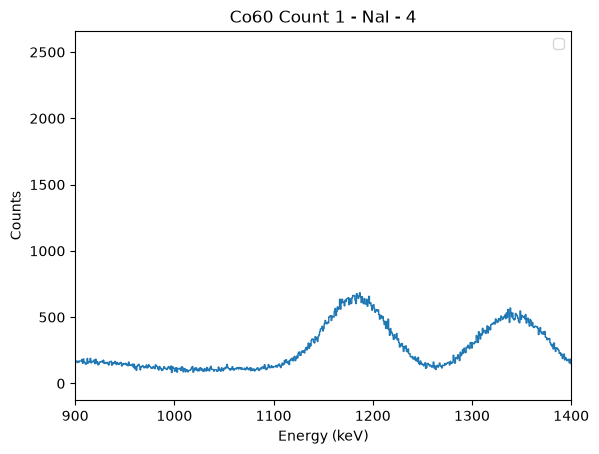

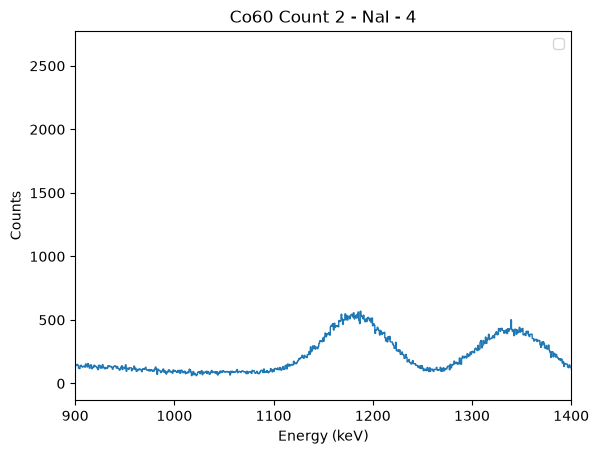

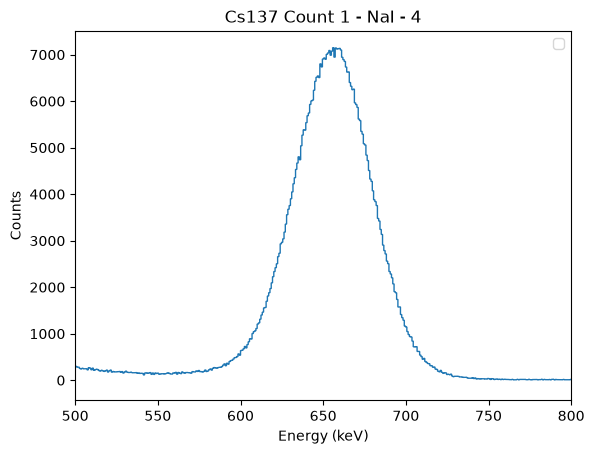

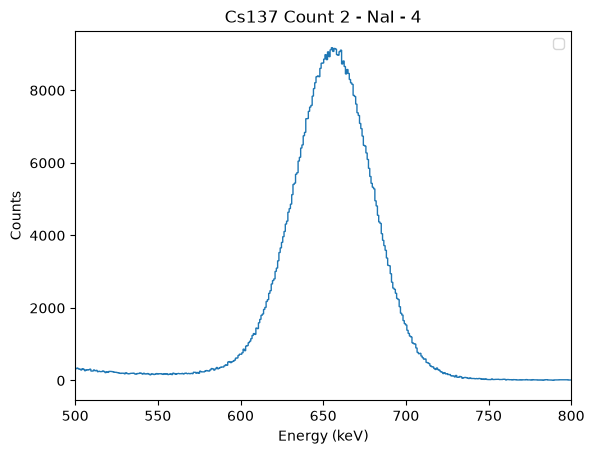

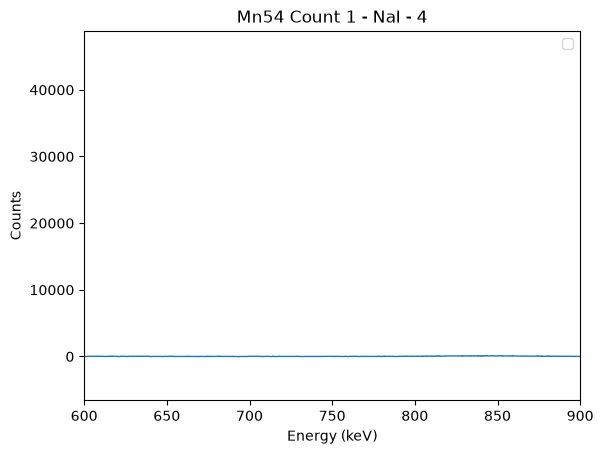

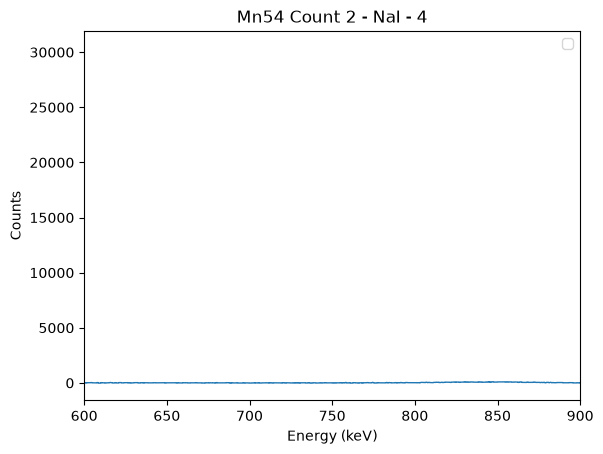

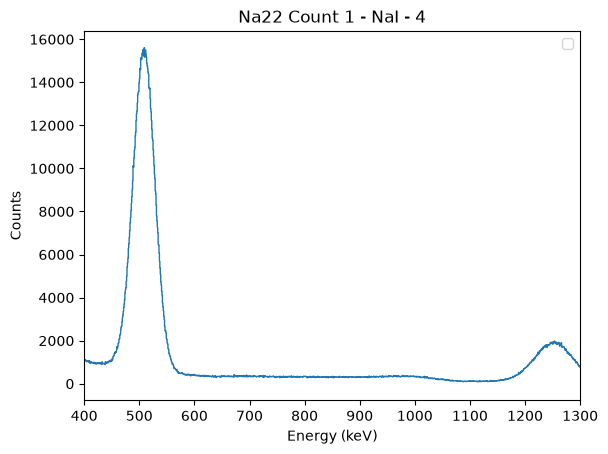

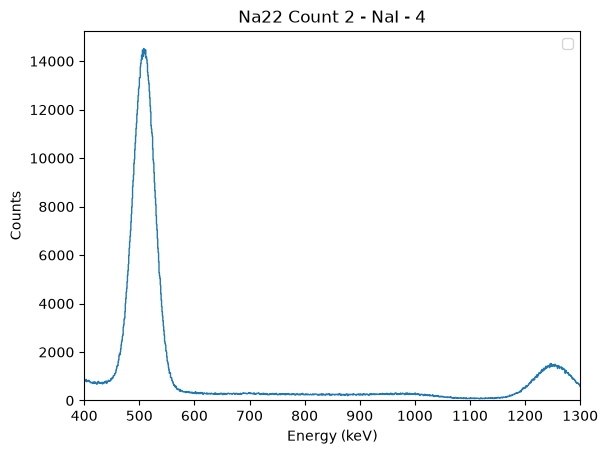

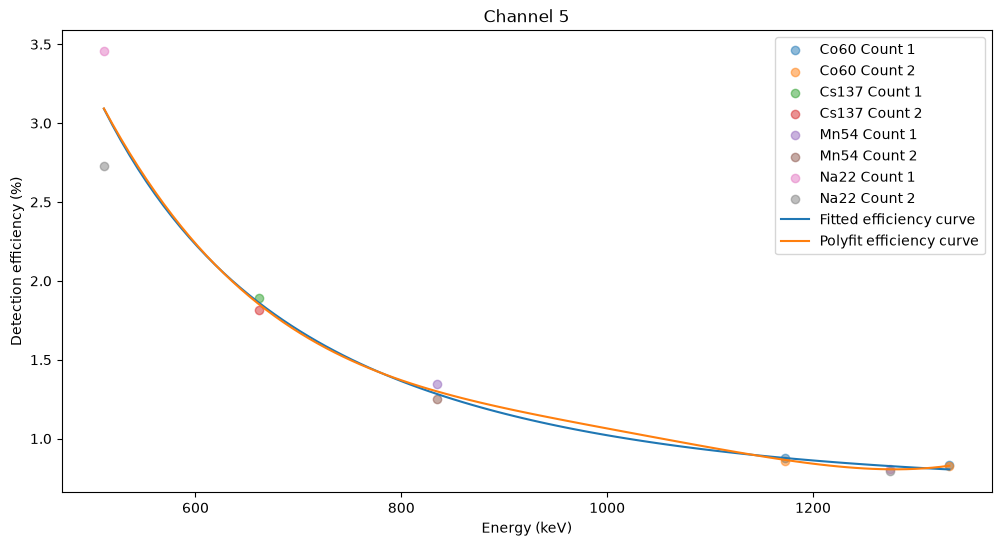

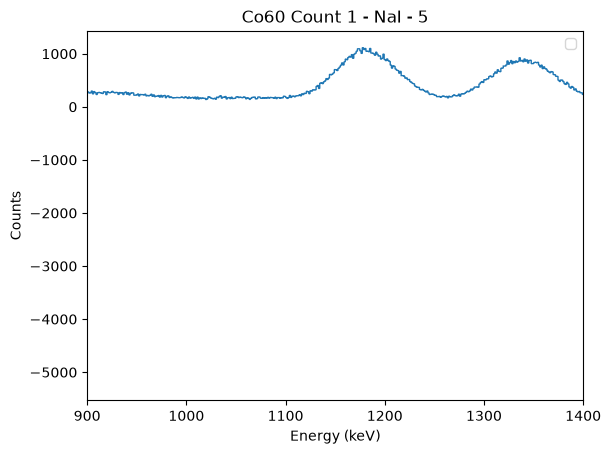

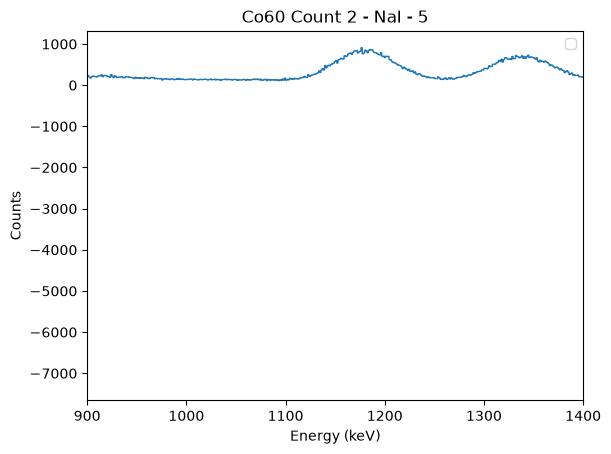

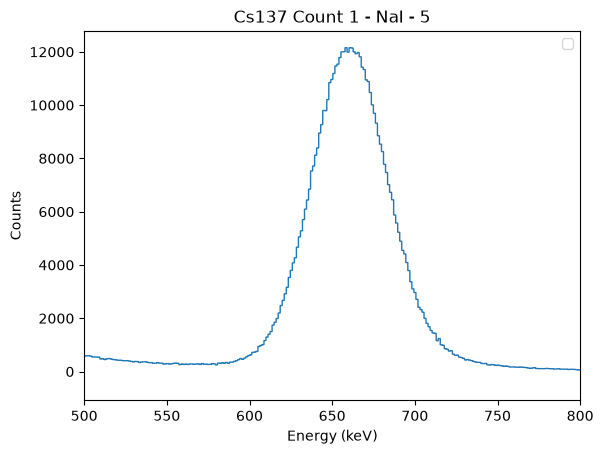

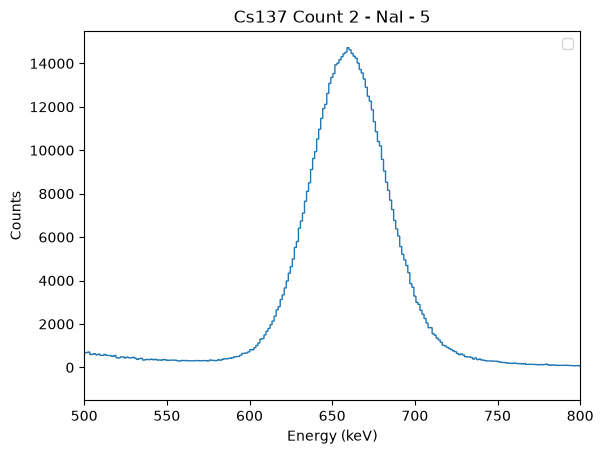

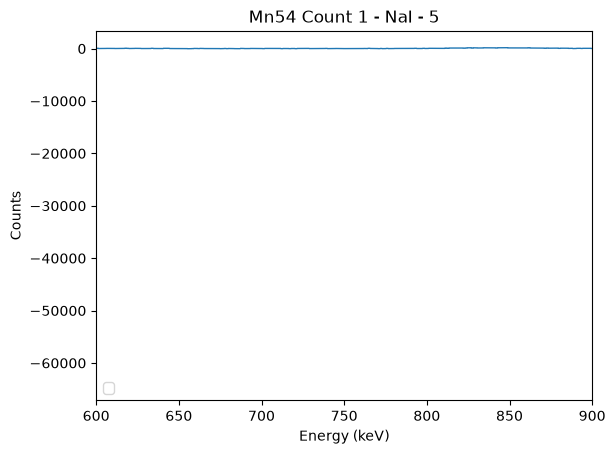

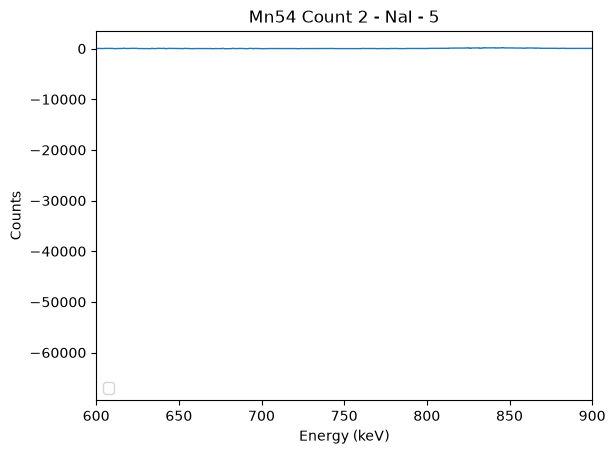

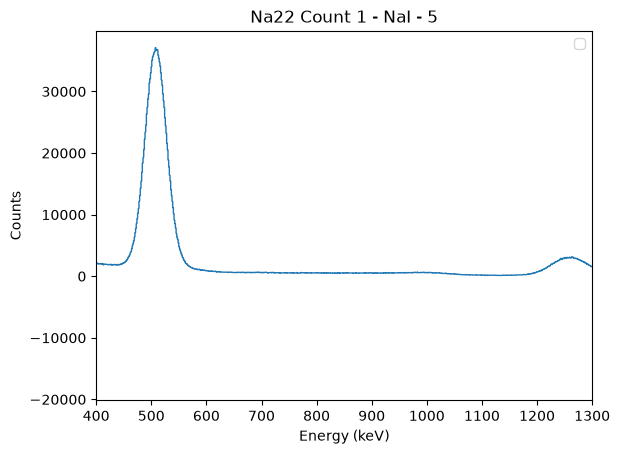

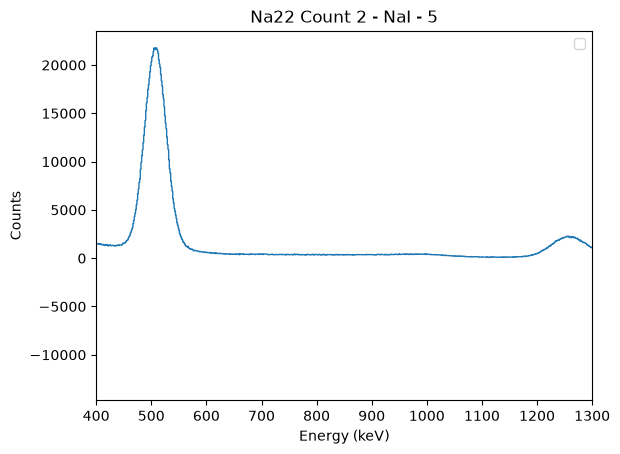

In [8]:
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

channels = []
efficiency_coeffs = {}
exp_efficiency_coeffs = {}
measurement = list(check_source_measurements.values())[0]

# search_widths = np.arange(20, 50, 2)
# for search_width in search_widths:
search_width = 300
threshold_overlap = 200
for detector in measurement.detectors:
    channels.append(detector.channel_nb)

xlim_dict = {
    'Ba133': [100, 500],
    'Co60': [900, 1400],
    'Cs137': [500, 800],
    'Mn54': [600, 900],
    'Na22': [400, 1300],
}

for channel_nb in channels:
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 6))

    background_detector = background_meas.get_detector(channel_nb)
    energies = []
    efficiencies = []
    for name, measurement in check_source_measurements.items():
        check_source_detector = measurement.get_detector(channel_nb)
        hist, bin_edges = check_source_detector.get_energy_hist_background_substract(background_detector, bins=None)
        calibrated_bin_edges = np.polyval(calibration_coeffs[channel_nb], bin_edges)

        # plot the histogram
        fig2,ax2 = plt.subplots()
        ax2.stairs(hist, calibrated_bin_edges)
        # ax2.set_xlim(left=0, right=500)

        # See how well calibrated peaks match expected energies
        expected_energies = measurement.check_source.nuclide.energy
        for energy in expected_energies:
            lower_ind = np.argmin(np.abs((energy - search_width) - calibrated_bin_edges))
            upper_ind = np.argmin(np.abs((energy + search_width) - calibrated_bin_edges))
            hist_search = hist[lower_ind:upper_ind]

            peaks, peak_params = find_peaks(hist_search, height=np.max(hist_search) * 0.5)

        # print('notebook search_width:', search_width, ' threshold_overlap:', threshold_overlap)

        # uncalibrated = np.array(
        #             measurement.check_source.nuclide._uncalibrated_measured_energies.get(channel_nb, []),
        #             dtype=float
        #         )
        # calibrated_ergs = np.polyval(calibration_coeffs[channel_nb], uncalibrated)


        ax2.set_xlabel("Energy (keV)")
        ax2.set_ylabel("Counts")
        ax2.set_title(f"{measurement.name} - {measurement.detector_type} - {channel_nb}")
        ax2.legend()
        nuclide = name.split()[0]
        if nuclide in xlim_dict:
            ax2.set_xlim(left=xlim_dict[nuclide][0], right=xlim_dict[nuclide][1])
        else:
            ax2.set_xlim(left=0, right=1500)
        
        efficiency = measurement.compute_detection_efficiency(
            background_measurement=background_meas,
            calibration_coeffs=calibration_coeffs[channel_nb],
            channel_nb=channel_nb,
            search_width=search_width,
            threshold_overlap=threshold_overlap,
            # summing_method='sum_gaussian',
            summing_method='sum_histogram'
        )
        print("\n" + "=" * 40)

        energies += measurement.check_source.nuclide.energy
        efficiencies += list(efficiency)
        ax.scatter(
            measurement.check_source.nuclide.energy,
            efficiency * 100,
            label=name,
            alpha=0.5
        )

    # Sort energies and efficiencies for fitting
    sorted_indices = np.argsort(energies)
    energies = np.array(energies)[sorted_indices]
    efficiencies = np.array(efficiencies)[sorted_indices]
    print(f"Ch {channel_nb} \n\t Energies: {energies}, \n\t Efficiencies: {efficiencies}")

    # Fit the efficiency curve
    popt, pcov = curve_fit(
        eff_curve_func,
        energies,
        efficiencies,
        p0=[-1, 1, 0, 0],
    )

    exp_efficiency_coeffs[channel_nb] = popt

    poly_coeff = np.polyfit(energies, efficiencies, 4)
    efficiency_coeffs[channel_nb] = poly_coeff
    xs = np.linspace(
        energies[0],
        energies[-1],
        100,
    )
    ax.plot(
        xs,
        eff_curve_func(xs, *popt) * 100,
        label="Fitted efficiency curve",
    )

    ax.plot(
        xs,
        np.polyval(poly_coeff, xs) * 100,
        label="Polyfit efficiency curve",
    )
    ax.set_xlabel("Energy (keV)")
    ax.set_ylabel("Detection efficiency (%)")
    ax.set_title(f"Channel {channel_nb}")
    ax.legend()
    # plt.ylim(bottom=0)
    print(popt)
plt.show()

## Calculating average neutron rate from activation foils

First, the irradiation schedule and the foil information is collected.

In [9]:
all_neutron_rates = []
all_neutron_rates_err = []

## Irradiation Time

In [10]:
from process_foil_data import irradiations
print("Irradiation schedule from process_foil_data.py:")
for i, irrad in enumerate(irradiations):
    print(f"  {i+1}. {irrad['t_on']} - {irrad['t_off']}")
# irradiations = [
#     {'t_on': 0.0, 't_off': 100.0},
#     {'t_on': 150.0, 't_off': 300.0}]

Irradiation schedule from process_foil_data.py:
  1. 0.0 - 6960.0
  2. 7020.0 - 7320.0
  3. 7380.0 - 8700.0
  4. 10080.0 - 11400.0
  5. 11520.0 - 17100.0
  6. 18000.0 - 19680.0
  7. 19740.0 - 20940.0
  8. 23220.0 - 41700.0


### Zirconium Packet #9 Results

The activity of Zr-89 is measured using its 909 keV gamma peak and used to determine the neutron rate during the irradiation. Zr-89 is formed from the Zr-90(n,2n) reaction, which has a threshold energy of ~12 MeV. 

The gamma spectrum obtained from the various measurements of the Zirconium Packet #3 after irradiation are used to calculate the neutron rate of the overall irradiation. 

In [11]:
# Evaluate efficiency function at the energies of interest for each channel
print("Zirconium efficiencies:")
zr_energy = foil_measurements["Zirconium Packet #9"]["foil"].reaction.product.energy[0]
for ch in channels:
    efficiency = eff_curve_func(zr_energy, *exp_efficiency_coeffs[ch])
    print(f"\tChannel {ch}: {efficiency}")

print("Niobium efficiencies:")
nb_energy = foil_measurements["Niobium Packet #11"]["foil"].reaction.product.energy[0]
for ch in channels:
    efficiency = eff_curve_func(nb_energy, *exp_efficiency_coeffs[ch])
    print(f"\tChannel {ch}: {efficiency}")


Zirconium efficiencies:
	Channel 4: 0.007599347534428922
	Channel 5: 0.011436322097515472
Niobium efficiencies:
	Channel 4: 0.00734654388381851
	Channel 5: 0.011051583045736526


In [12]:
from process_foil_data import calculate_neutron_rate_from_foil

foil_name = "Zirconium Packet #9"
efficiency_coeffs = {ch: None for ch in calibration_coeffs.keys()} # Use the efficiency function definition
neutron_rates, neutron_rate_errs = calculate_neutron_rate_from_foil(foil_measurements,
                                                                    foil_name,
                                                                    background_meas,
                                                                    calibration_coeffs,
                                                                    efficiency_coeffs,
                                                                    search_width=search_width,
                                                                    irradiations=irradiations,
                                                                    efficiency_function=eff_curve_func,
                                                                    efficiency_function_args=exp_efficiency_coeffs)

for count_name in neutron_rates.keys():
    print(count_name)
    for ch in np.sort(list(neutron_rates[count_name].keys())):
        neutron_rate = neutron_rates[count_name][ch]
        neutron_rate_err = neutron_rate_errs[count_name][ch]
        print(f"\t Ch {ch}: Neutron rate: {neutron_rate[0]:.3e} +/- {neutron_rate_err[0]:.3e} n/s")
        all_neutron_rates.append(neutron_rate[0])
        all_neutron_rates_err.append(neutron_rate_err[0])


[909.15]
Fitted parameters: [ 1.28305940e+02 -1.06997428e-01  4.26328404e+02  9.22948173e+02
  2.80599388e+01]
[909.15]
Fitted parameters: [ 2.24389867e+02 -1.91215937e-01  6.76802586e+02  9.20138449e+02
  2.68743790e+01]
[909.15]
Fitted parameters: [ 1.00519932e+02 -8.78557020e-02  3.65078813e+02  9.20401220e+02
  2.81030633e+01]
[909.15]
Fitted parameters: [ 1.59848066e+02 -1.40392754e-01  5.94928420e+02  9.20145832e+02
  2.67614014e+01]
Count 1
	 Ch 4: Neutron rate: 4.738e+08 +/- 2.740e+06 n/s
	 Ch 5: Neutron rate: 4.790e+08 +/- 2.247e+06 n/s
Count 2
	 Ch 4: Neutron rate: 4.682e+08 +/- 2.924e+06 n/s
	 Ch 5: Neutron rate: 4.830e+08 +/- 2.421e+06 n/s


### Zirconium Packet #11 Results

The activity of Zr-89 is measured using its 909 keV gamma peak and used to determine the neutron rate during the irradiation. Zr-89 is formed from the Zr-90(n,2n) reaction, which has a threshold energy of 12.1 MeV. 

The gamma spectrum obtained from the various measurements of the Zirconium Packet #1 after irradiation are used to calculate the neutron rate of the overall irradiation. 

In [13]:
foil_name = "Zirconium Packet #10"

neutron_rates, neutron_rate_errs = calculate_neutron_rate_from_foil(foil_measurements,
                                                                    foil_name,
                                                                    background_meas,
                                                                    calibration_coeffs,
                                                                    efficiency_coeffs,
                                                                    search_width=search_width,
                                                                    irradiations=irradiations,
                                                                    efficiency_function=eff_curve_func,
                                                                    efficiency_function_args=exp_efficiency_coeffs)

for count_name in neutron_rates.keys():
    print(count_name)
    for ch in np.sort(list(neutron_rates[count_name].keys())):
        neutron_rate = neutron_rates[count_name][ch]
        neutron_rate_err = neutron_rate_errs[count_name][ch]
        print(f"\t Ch {ch}: Neutron rate: {neutron_rate[0]:.3e} +/- {neutron_rate_err[0]:.3e} n/s")
        all_neutron_rates.append(neutron_rate[0])
        all_neutron_rates_err.append(neutron_rate_err[0])

[909.15]
Fitted parameters: [ 1.58082806e+02 -1.37644124e-01  5.71118316e+02  9.21033890e+02
  2.79472841e+01]
[909.15]
Fitted parameters: [ 2.84162901e+02 -2.54481627e-01  9.64289553e+02  9.18003162e+02
  2.65733950e+01]
[909.15]
Fitted parameters: [ 9.67875656e+01 -8.66978425e-02  3.62433258e+02  9.19123015e+02
  2.83553984e+01]
[909.15]
Fitted parameters: [ 1.78523006e+02 -1.60104773e-01  5.77639466e+02  9.21465142e+02
  2.66851472e+01]
Count 1
	 Ch 4: Neutron rate: 3.818e+08 +/- 1.912e+06 n/s
	 Ch 5: Neutron rate: 4.076e+08 +/- 1.611e+06 n/s
Count 2
	 Ch 4: Neutron rate: 3.940e+08 +/- 2.458e+06 n/s
	 Ch 5: Neutron rate: 3.930e+08 +/- 2.002e+06 n/s


In [14]:
foil_name = "Niobium Packet #11"

neutron_rates, neutron_rate_errs = calculate_neutron_rate_from_foil(foil_measurements,
                                                                    foil_name,
                                                                    background_meas,
                                                                    calibration_coeffs,
                                                                    efficiency_coeffs,
                                                                    search_width=search_width,
                                                                    irradiations=irradiations,
                                                                    efficiency_function=eff_curve_func,
                                                                    efficiency_function_args=exp_efficiency_coeffs)

for count_name in neutron_rates.keys():
    print(count_name)
    for ch in np.sort(list(neutron_rates[count_name].keys())):
        neutron_rate = neutron_rates[count_name][ch]
        neutron_rate_err = neutron_rate_errs[count_name][ch]
        print(f"\t Ch {ch}: Neutron rate: {neutron_rate[0]:.3e} +/- {neutron_rate_err[0]:.3e} n/s")
        all_neutron_rates.append(neutron_rate[0])
        all_neutron_rates_err.append(neutron_rate_err[0])

[934.44]
Fitted parameters: [ 3.02110176e+02 -2.67240792e-01  1.19164615e+03  9.41191689e+02
  2.89937457e+01]
[934.44]
Fitted parameters: [ 4.87768117e+02 -4.23760803e-01  1.89591005e+03  9.43750531e+02
  2.77499337e+01]
[934.44]
Fitted parameters: [ 2.37488978e+02 -2.15158163e-01  9.51916158e+02  9.36376760e+02
  2.87138159e+01]
[934.44]
Fitted parameters: [ 3.77004956e+02 -3.33539325e-01  1.48376155e+03  9.41502923e+02
  2.77042498e+01]
Count 1
	 Ch 4: Neutron rate: 4.862e+08 +/- 1.655e+06 n/s
	 Ch 5: Neutron rate: 4.926e+08 +/- 1.358e+06 n/s
Count 2
	 Ch 4: Neutron rate: 4.882e+08 +/- 1.868e+06 n/s
	 Ch 5: Neutron rate: 4.886e+08 +/- 1.524e+06 n/s


In [15]:
foil_name = "Niobium Packet #12"

neutron_rates, neutron_rate_errs = calculate_neutron_rate_from_foil(foil_measurements,
                                                                    foil_name,
                                                                    background_meas,
                                                                    calibration_coeffs,
                                                                    efficiency_coeffs,
                                                                    search_width=search_width,
                                                                    irradiations=irradiations,
                                                                    efficiency_function=eff_curve_func,
                                                                    efficiency_function_args=exp_efficiency_coeffs)

for count_name in neutron_rates.keys():
    print(count_name)
    for ch in np.sort(list(neutron_rates[count_name].keys())):
        neutron_rate = neutron_rates[count_name][ch]
        neutron_rate_err = neutron_rate_errs[count_name][ch]
        print(f"\t Ch {ch}: Neutron rate: {neutron_rate[0]:.3e} +/- {neutron_rate_err[0]:.3e} n/s")
        all_neutron_rates.append(neutron_rate[0])
        all_neutron_rates_err.append(neutron_rate_err[0])

[934.44]
Fitted parameters: [ 1.46375846e+02 -1.28531050e-01  5.98593898e+02  9.41131967e+02
  2.91030876e+01]
[934.44]
Fitted parameters: [ 2.34640779e+02 -2.05498155e-01  9.36726100e+02  9.44103761e+02
  2.74945060e+01]
[934.44]
Fitted parameters: [ 2.13350607e+02 -1.96187092e-01  9.26820203e+02  9.31351341e+02
  2.88780643e+01]
[934.44]
Fitted parameters: [ 3.24552012e+02 -2.95026762e-01  1.43212225e+03  9.37479574e+02
  2.75421804e+01]
Count 1
	 Ch 4: Neutron rate: 5.516e+08 +/- 2.643e+06 n/s
	 Ch 5: Neutron rate: 5.424e+08 +/- 2.138e+06 n/s
Count 2
	 Ch 4: Neutron rate: 5.486e+08 +/- 2.121e+06 n/s
	 Ch 5: Neutron rate: 5.374e+08 +/- 1.712e+06 n/s


### Averaging foil results

The average of the neutron rates of the Niobium and Zirconium foil packets is calculated and added to the processed_data.json file. 

In [16]:
average_neutron_rate = np.mean(all_neutron_rates)
# average_neutron_rate_err = np.sqrt(np.sum(np.array(all_neutron_rates_err) ** 2)) / len(all_neutron_rates_err)
average_neutron_rate_err = np.std(all_neutron_rates, ddof=1)  # Use ddof=1 for sample standard deviation

print(f"Average neutron rate: {average_neutron_rate:.3e} ± {average_neutron_rate_err:.3e} n/s")

total_irradiation_time = sum(irrad['t_off'] - irrad['t_on'] for irrad in irradiations)
print(f"\nTotal irradiation time (from schedule): {total_irradiation_time:.2f} seconds")
print("Total neutrons (approximate): {:.3e} +/- {:.2e}".format(
      total_irradiation_time * average_neutron_rate,
      total_irradiation_time * average_neutron_rate_err))

Average neutron rate: 4.760e+08 ± 5.605e+07 n/s

Total irradiation time (from schedule): 36840.00 seconds
Total neutrons (approximate): 1.754e+13 +/- 2.06e+12


In [17]:
processed_data_file = "../../data/processed_data.json"

processed_data = {
    "neutron_rate_used_in_model": {
        "value":average_neutron_rate,
        "error": average_neutron_rate_err,
        "unit": "neutron / second"
    }
}

try:
    with open(processed_data_file, "r") as f:
        existing_data = json.load(f)
except FileNotFoundError:
    print(f"Processed data file not found, creating it in {processed_data_file}")
    existing_data = {}

existing_data.update(processed_data)

with open(processed_data_file, "w") as f:
    json.dump(existing_data, f, indent=4)

print(f"Processed data stored in {processed_data_file}")

Processed data stored in ../../data/processed_data.json
